# Results and figures

This notebook reproduces every result in the [README](../README.md) from the stored data: the best input and output for
each function, the progress figures, the count of new bests each week, and the check of the model's predictions against
what came back. Nothing here is typed in by hand except the log of predictions in `src/figures.py`, which comes from the
console output I saved before each weekly query.

It rewrites the figures in `results/figures/` and `results/prediction_log.csv`, which should come out identical.

In [1]:
import csv
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # the notebook runs from notebooks/, the code lives in src/

import numpy as np
from IPython.display import Image, display

import figures
from data_io import load_week
from paths import FIGURES, RESULTS, latest_week

N_WEEKS = latest_week()
history = {w: load_week(w) for w in range(1, N_WEEKS + 1)}
print("weeks of data:", N_WEEKS)

weeks of data: 13


## Best input and output for each function

Inputs are written in the capstone's submission format, x1-x2-...-xn. The week is when that query was made.

In [2]:
print(f"{'Function':<10}{'Best output':<14}{'Week':<6}Best input")
for f in range(1, 9):
    X, y = history[N_WEEKS][f]
    i = int(np.argmax(y))
    n_initial = len(history[1][f][1]) - 1
    week = i - n_initial + 1 if i >= n_initial else "initial"
    print(f"F{f:<9}{y[i]:<14.6g}{str(week):<6}{'-'.join(f'{v:.6f}' for v in X[i])}")

Function  Best output   Week  Best input
F1        0.000142778   11    0.580530-0.579941
F2        0.741858      13    0.699500-0.909500
F3        -0.0054104    9     0.401915-0.392969-0.455665
F4        0.714132      13    0.361506-0.417260-0.411229-0.408367
F5        4246.41       13    0.443723-0.974215-1.000000-1.000000
F6        -0.0574688    12    0.457292-0.383089-0.649005-0.785017-0.140272
F7        2.75441       13    0.046509-0.182924-0.282867-0.276940-0.284300-0.674593
F8        9.97458       13    0.177156-0.134345-0.109926-0.135300-0.935393-0.535055-0.174600-0.640185


## New bests each week

A function sets a "new best" in a week when its best output so far rises. Most of the gains came after the switch to
small steps around each best point in Week 8.

In [3]:
initial_best = {f: history[1][f][1][:-1].max() for f in range(1, 9)}
previous = dict(initial_best)
per_week = []
for w in range(1, N_WEEKS + 1):
    new = [f for f in range(1, 9) if history[w][f][1].max() > previous[f]]
    per_week.append(len(new))
    print(f"Week {w:>2}: {len(new)} new best(s)  " + ", ".join(f"F{f}" for f in new))
    previous = {f: history[w][f][1].max() for f in range(1, 9)}
print()
print("total:", sum(per_week), "| from Week 8 onwards:", sum(per_week[7:]))

Week  1: 3 new best(s)  F4, F5, F8
Week  2: 3 new best(s)  F4, F6, F7
Week  3: 3 new best(s)  F4, F7, F8
Week  4: 0 new best(s)  
Week  5: 2 new best(s)  F3, F8
Week  6: 1 new best(s)  F6
Week  7: 3 new best(s)  F1, F3, F8
Week  8: 8 new best(s)  F1, F2, F3, F4, F5, F6, F7, F8
Week  9: 5 new best(s)  F3, F4, F5, F7, F8
Week 10: 3 new best(s)  F5, F7, F8
Week 11: 6 new best(s)  F1, F4, F5, F6, F7, F8
Week 12: 4 new best(s)  F5, F6, F7, F8
Week 13: 5 new best(s)  F2, F4, F5, F7, F8

total: 46 | from Week 8 onwards: 31


## Figures

Rebuilding all five from the data.

In [4]:
print("Saved:", *figures.build_all())

Saved: fig1_best_so_far.png fig2_progress_all_functions.png fig3_exploration_vs_exploitation.png fig4_f1_map.png fig5_prediction_error.png


**Figure 1, best output so far by week.** The long flat stretches before Week 8 are the evidence for switching from
exploring to exploiting around each best point. F1 is shown on a log scale.

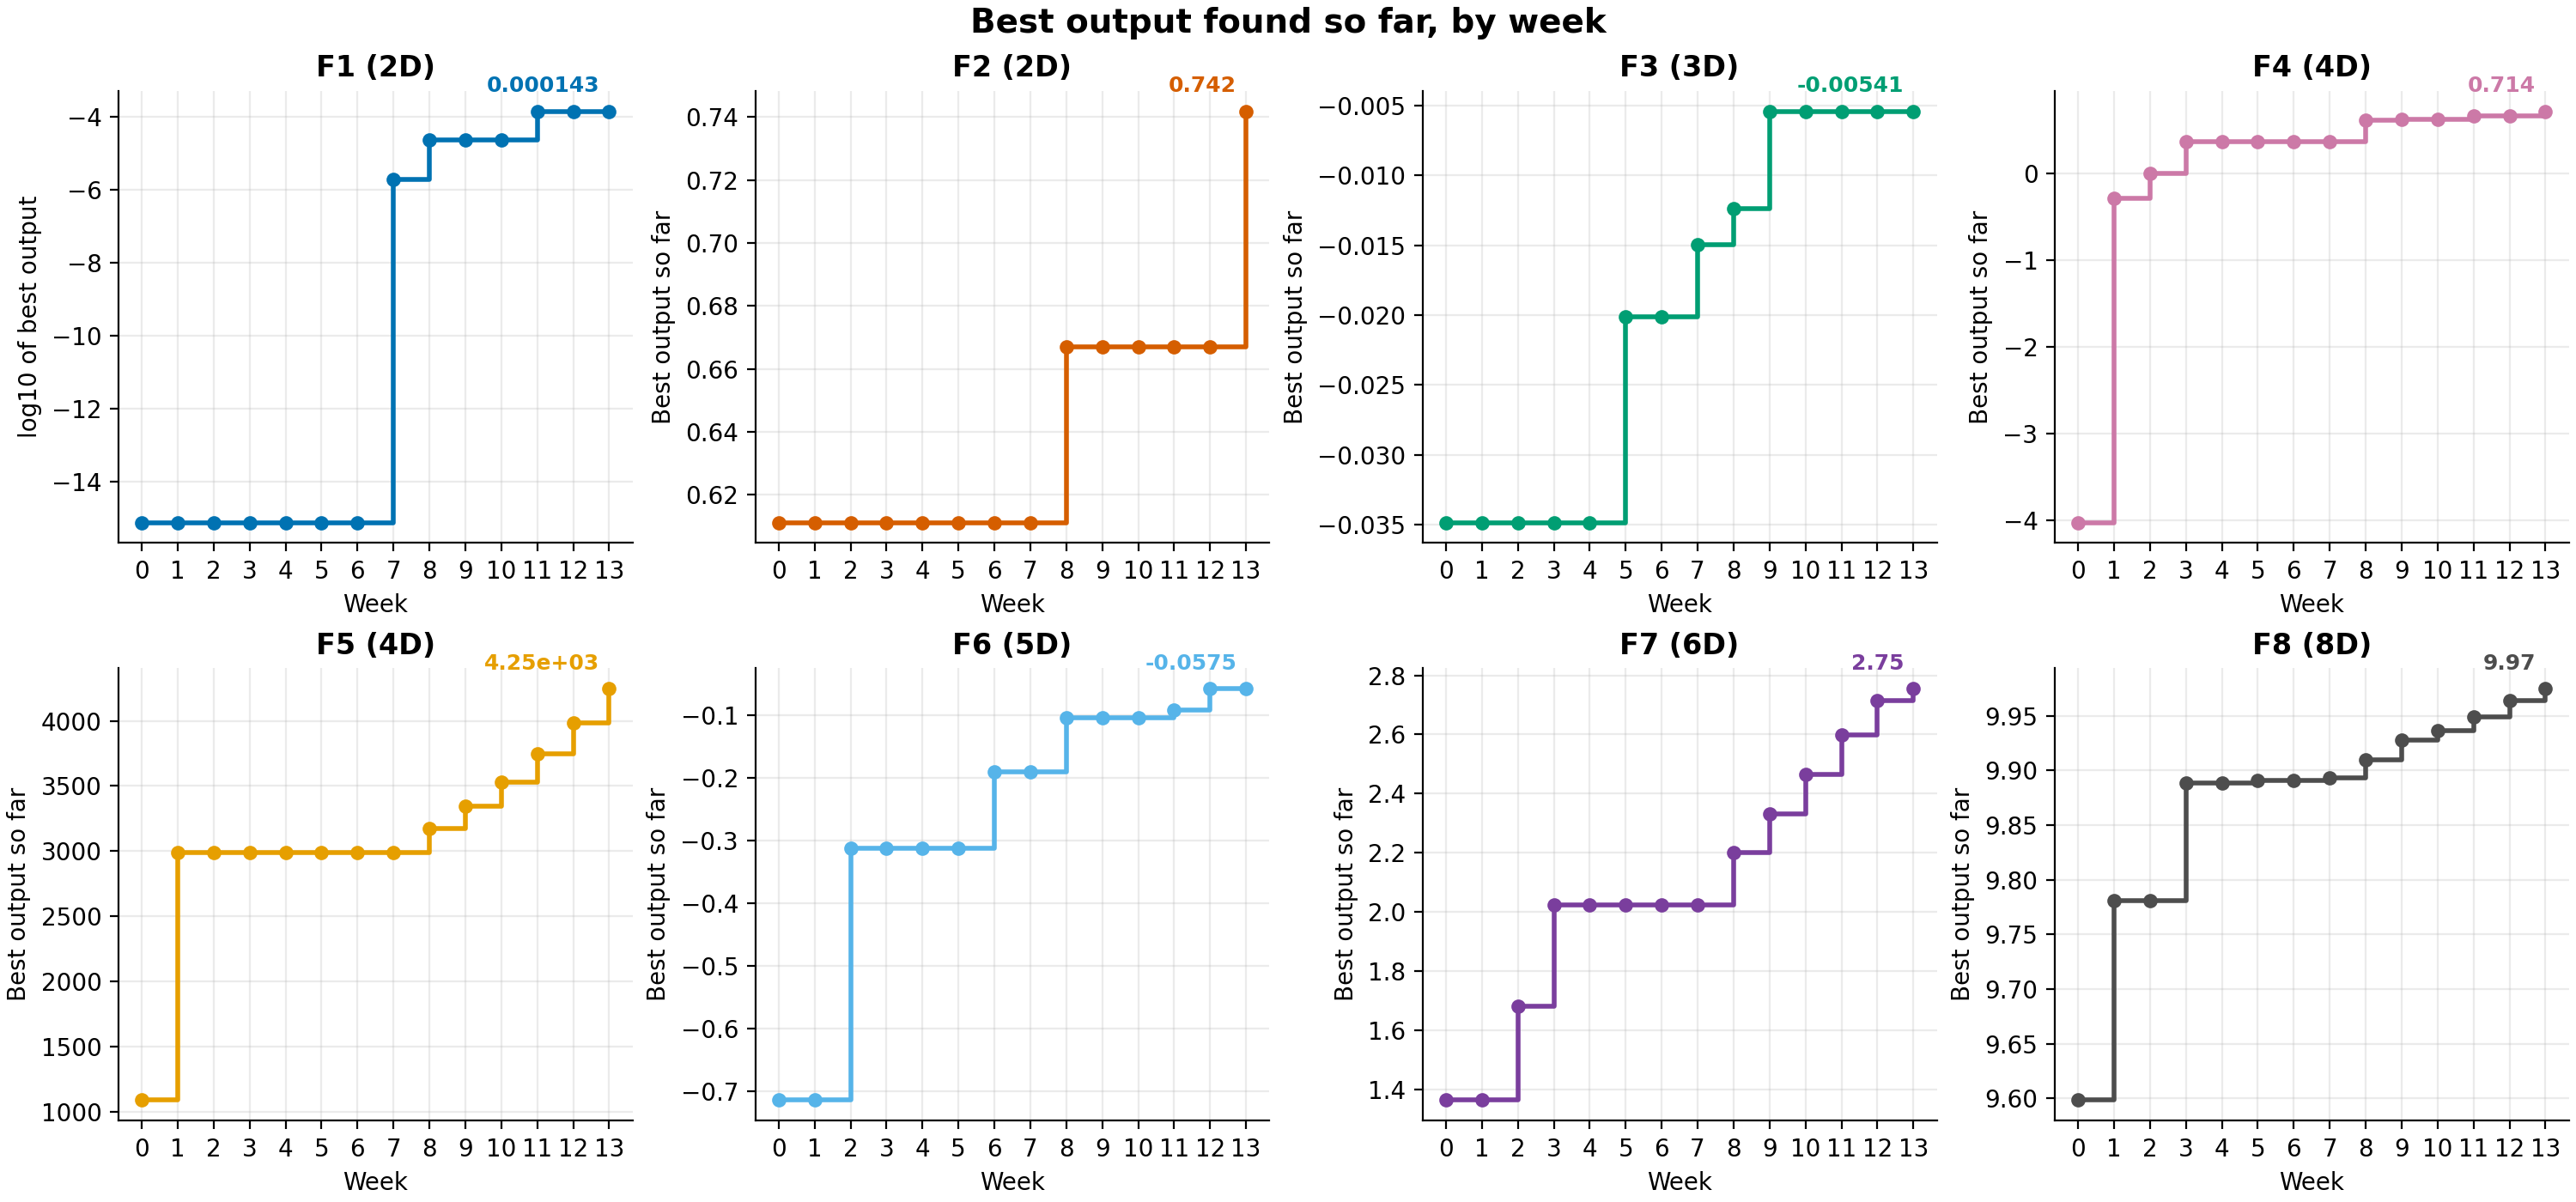

In [5]:
display(Image(filename=str(FIGURES / 'fig1_best_so_far.png')))

**Figure 2, progress for every function.** Putting all eight on one 0 to 1 scale shows which functions were still
improving and which had stalled.

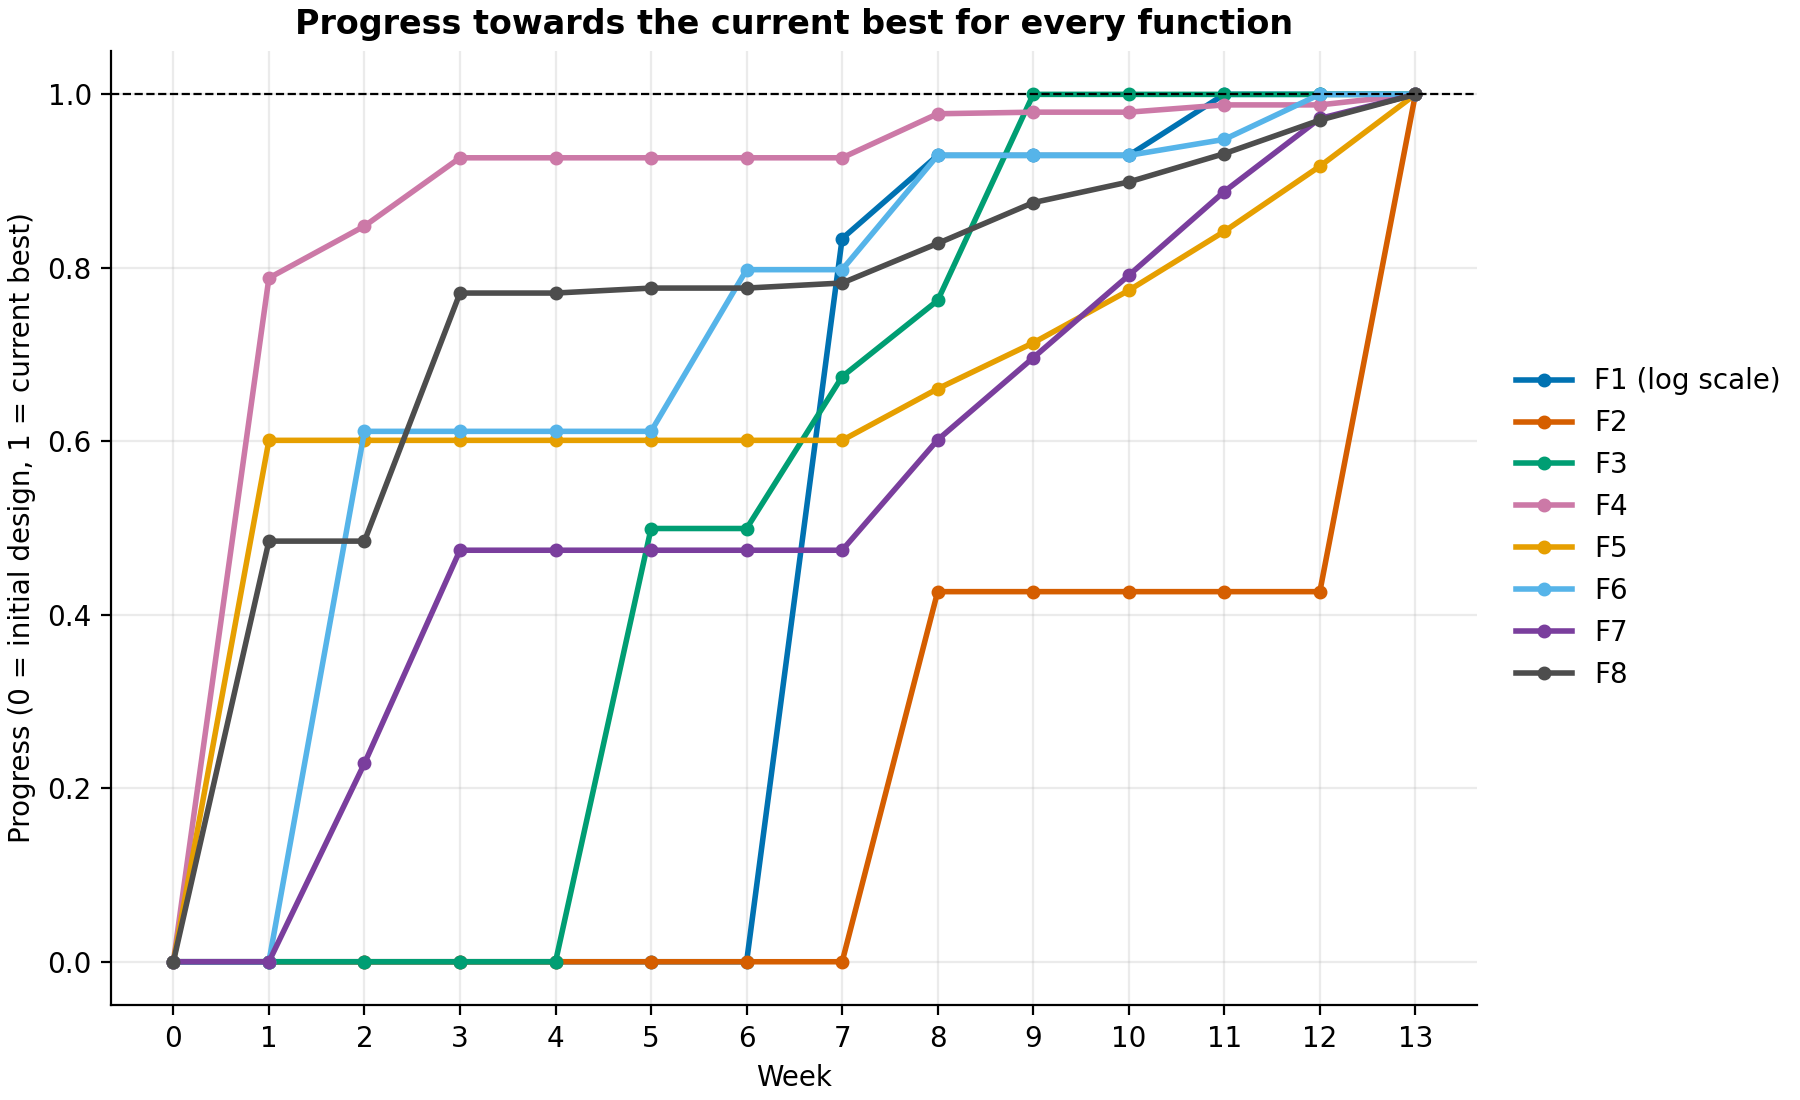

In [6]:
display(Image(filename=str(FIGURES / 'fig2_progress_all_functions.png')))

**Figure 3, exploration versus exploitation.** The drop in the distance from the previous best from Week 8 is the
evidence for the small-step plan.

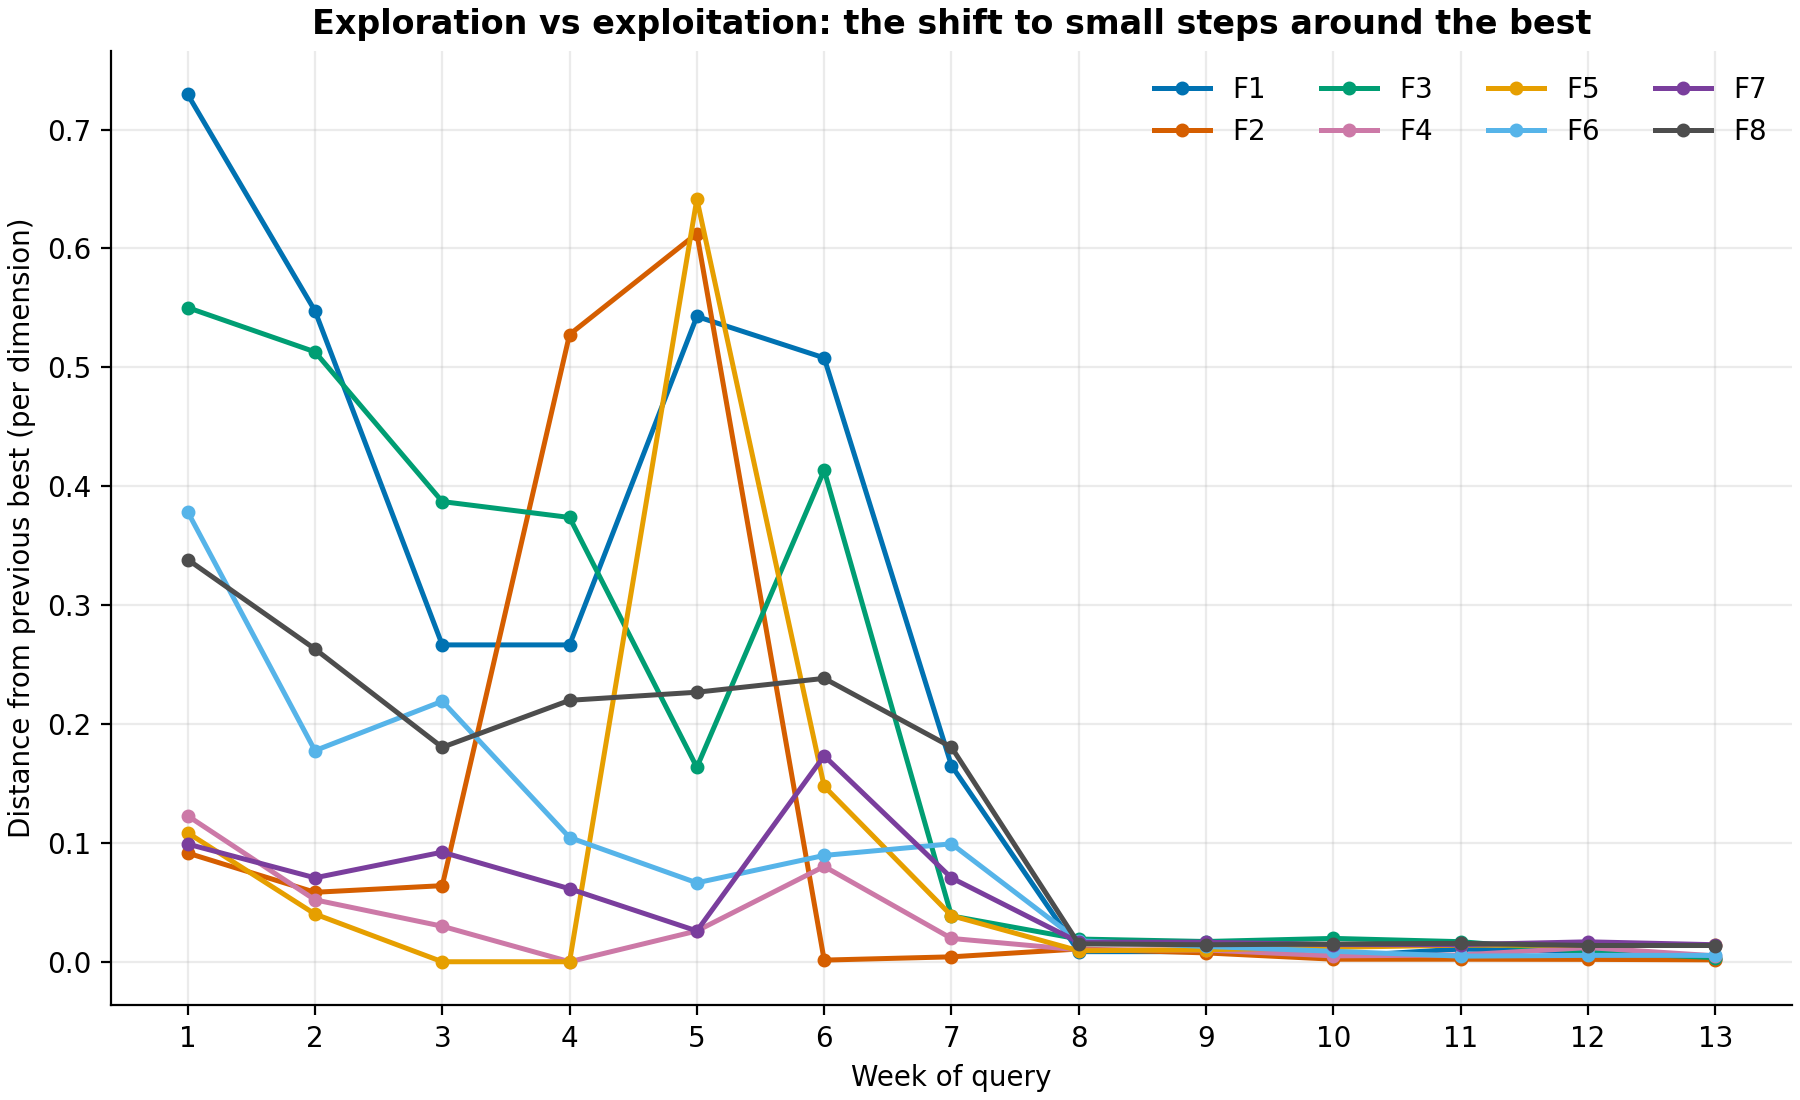

In [7]:
display(Image(filename=str(FIGURES / 'fig3_exploration_vs_exploitation.png')))

**Figure 4, the F1 map.** Almost every point is effectively zero, with a narrow stripe of signal, which is why I
stopped using model-based picks for F1 and switched to a small-step pattern search.

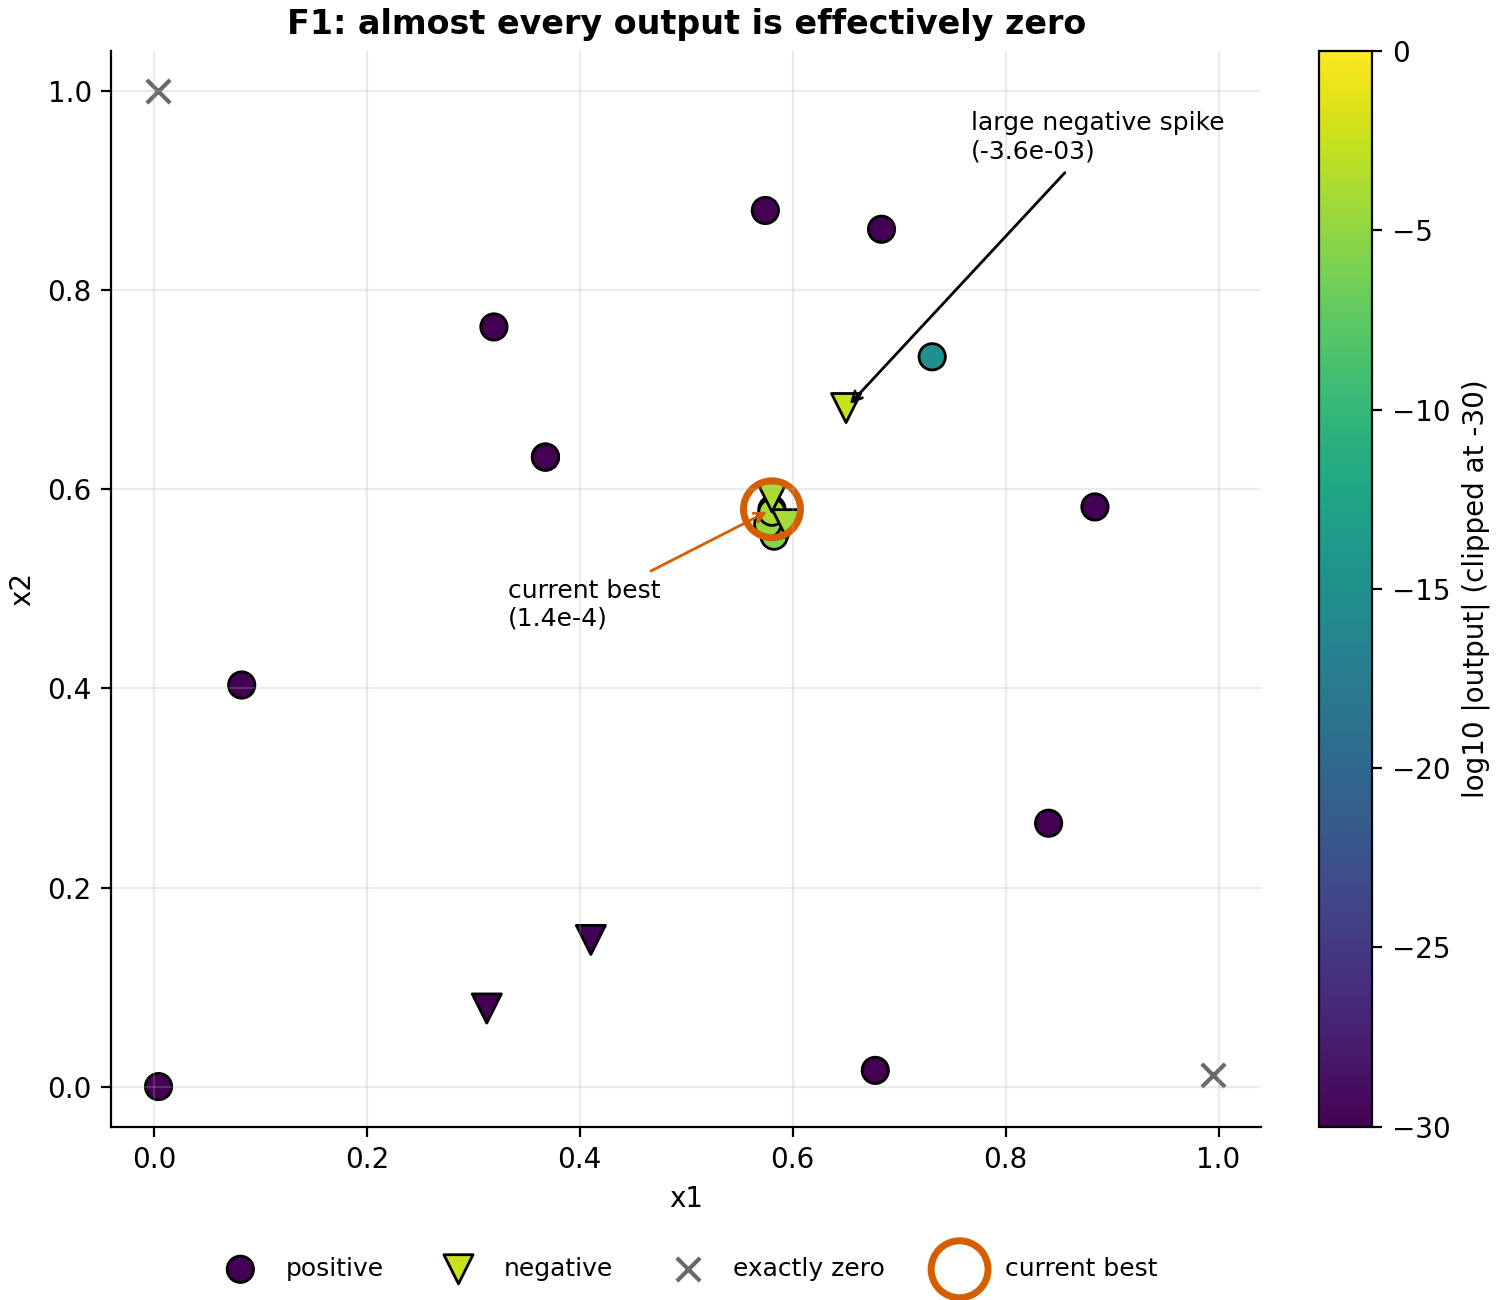

In [8]:
display(Image(filename=str(FIGURES / 'fig4_f1_map.png')))

## How good were the predictions?

Before each weekly query I recorded the model's predicted output and uncertainty for the point I chose. When the real
output came back I measured the error in standard deviations, `(actual - predicted) / predicted std`. This is the only
out-of-sample check available, because the real output was never used to fit the prediction it is compared with.
A well-calibrated model would be within one standard deviation about 68% of the time. F1 is left out, because its
predictions are on a different scale.

In [9]:
with open(RESULTS / "prediction_log.csv", newline="") as fh:
    rows = [r for r in csv.DictReader(fh) if r["function"] != "1"]

print(f"{'Model':<8}{'Predictions':<13}{'Within 1 std':<14}{'Within 2 std':<14}Mean |error| in std")
for model in ("GP", "RF"):
    z = np.abs([float(r["z_score"]) for r in rows if r["model"] == model])
    print(f"{model:<8}{len(z):<13}{(z <= 1).mean():<14.0%}{(z <= 2).mean():<14.0%}{z.mean():.2f}")

Model   Predictions  Within 1 std  Within 2 std  Mean |error| in std
GP      39           49%           79%           1.44
RF      3            67%           100%          0.60


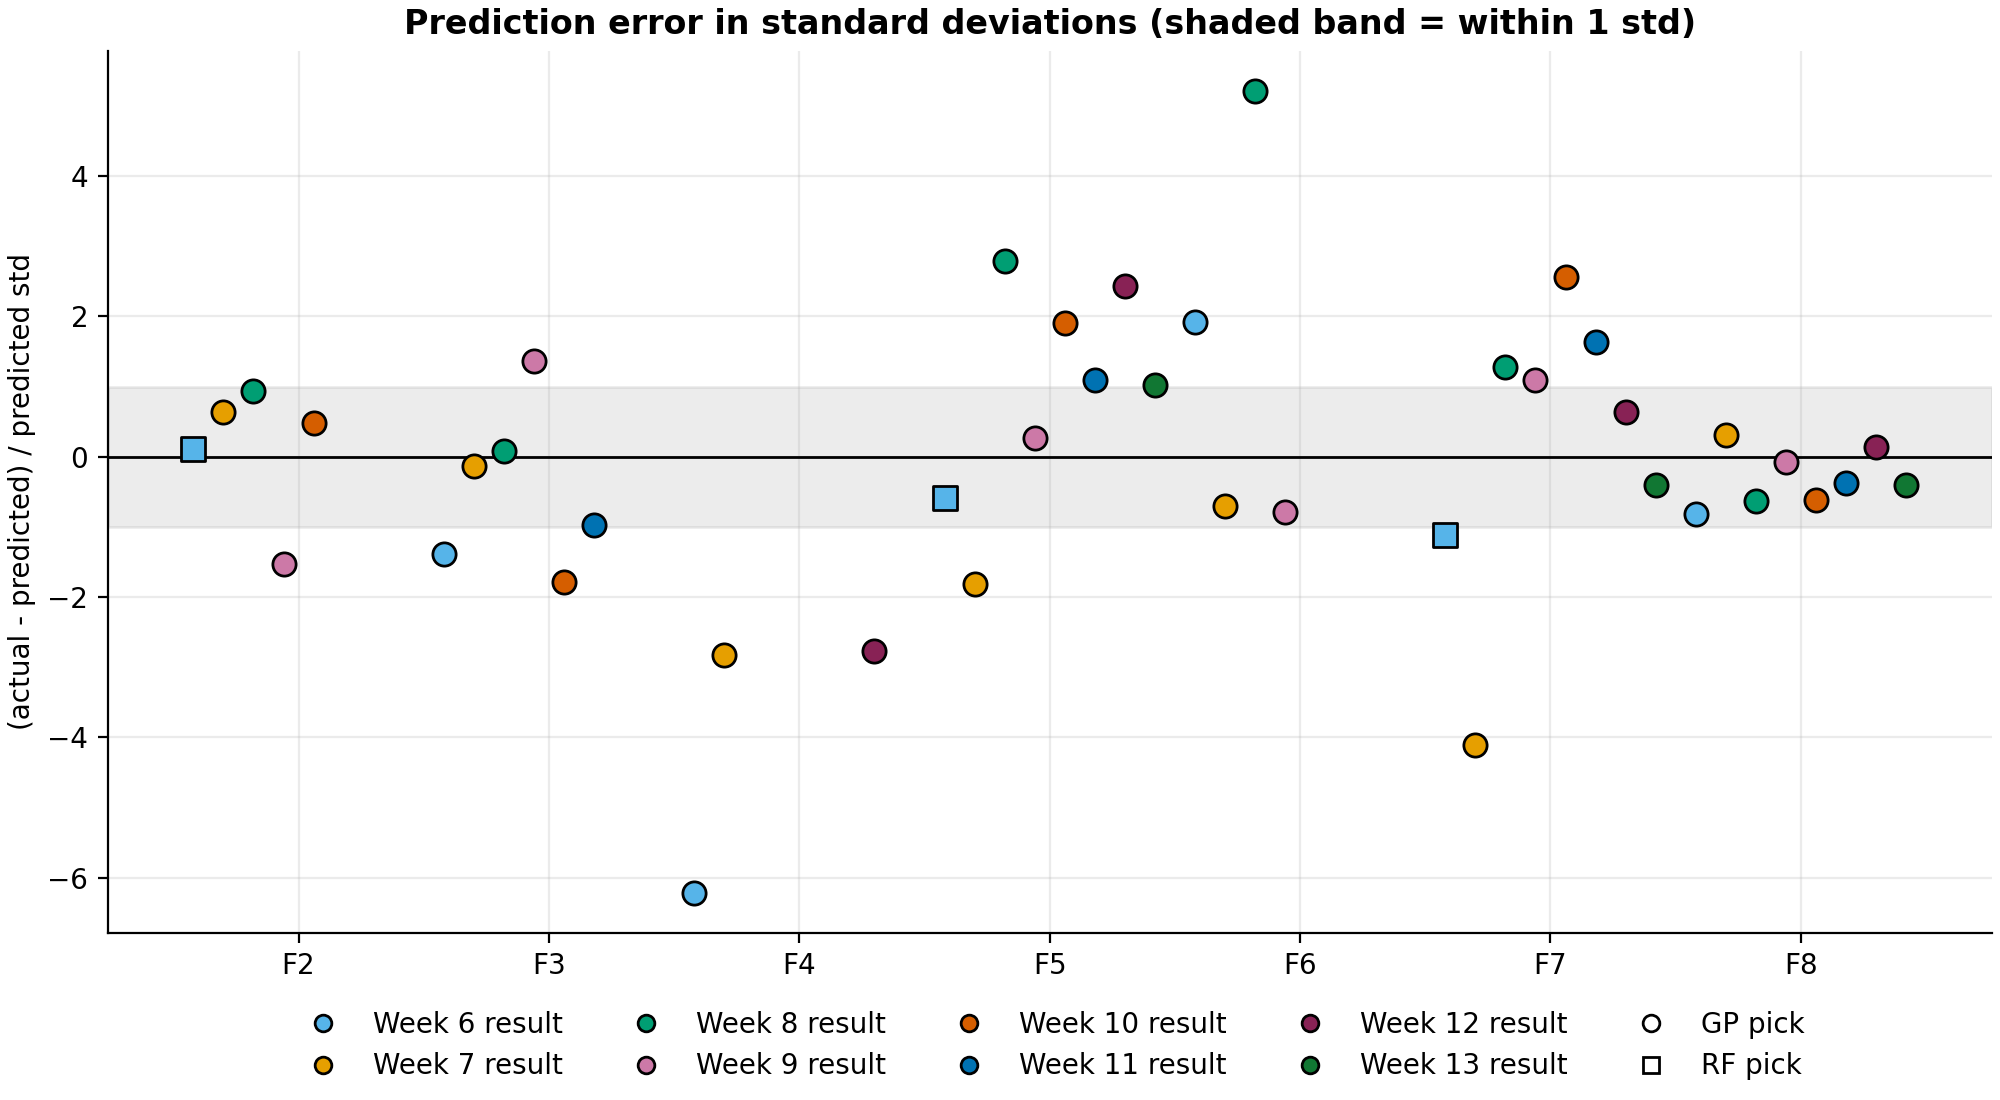

In [10]:
display(Image(filename=str(FIGURES / 'fig5_prediction_error.png')))

The Random Forest figures come from only three predictions, so they are not a reliable comparison with the Gaussian
Process. The Gaussian Process was within one standard deviation less often than a well-calibrated model would be, which
is why I treated its predictions as directions and not forecasts (see the model card).